In [19]:
import tensorflow as tf
import numpy as np
import pandas as pd


In [20]:
#importamos los datos desde un archivo .csv
datos = pd.read_csv("datos.csv")

In [21]:
# obtenemos informacion metadatos del tipo de datos que tenemos
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   celcius    7 non-null      int64  
 1   farenheit  7 non-null      float64
dtypes: float64(1), int64(1)
memory usage: 240.0 bytes


In [22]:
#obtenemos una vista previa de los datos
datos.head()

,celcius,farenheit
0,-40,-40.0
1,-10,14.0
2,0,32.0
3,8,46.4
4,15,59.0


<Axes: xlabel='celcius', ylabel='farenheit'>

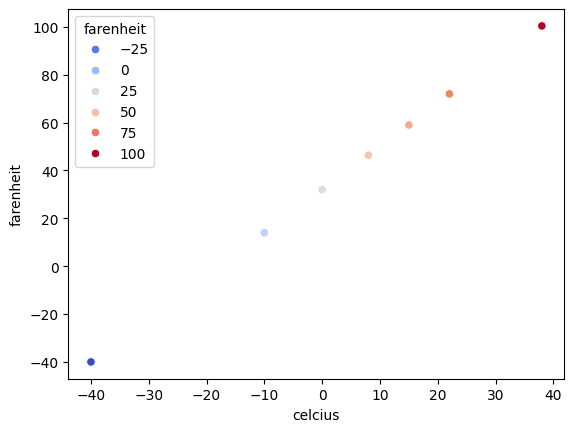

In [23]:
# Visualizamos los datos con seaborn
import seaborn as sb
sb.scatterplot(x='celcius',y='farenheit',data=datos, 
               hue='farenheit',     # Muestra el 
               palette='coolwarm')

In [25]:
#Preparamos los datos
celsius = np.array([-40, -10, 0, 8, 15, 22, 38], dtype=float)
fahrenheit = np.array([-40, 14, 32, 46.4, 59, 72, 100,4], dtype=float)

In [26]:
# Preparamos los datos separandolo en :
# 1.- Caracteristicas  (x) 
# 2.- Etiqueta o respuesta (y)
# En este ejemplo las caracteristicas solo hay 1 los grados Celcius, a diferencia de los precios
# de casas que tienen muchas caracteristicas para determinar un precio i.e: #de cuartos, M2, zona, etc.

x_celsius = datos['celcius']
y_farenheit = datos['farenheit']
x_celsius.values # rray([-40, -10,   0,   8,  15,  22,  38])

#NOTA : Aqui hay que darle formato a los datos y para eso los procesamos

array([-40, -10,   0,   8,  15,  22,  38])

In [27]:
#Damos formato a los valores de las caracteristicas es decir lo procesamos
x_celsius_procesada = x_celsius.values.reshape(-1,1)
x_farenheit_procesada = y_farenheit.values.reshape(-1,1)
x_farenheit_procesada

array([[-40. ],
       [ 14. ],
       [ 32. ],
       [ 46.4],
       [ 59. ],
       [ 72. ],
       [100.4]])

In [29]:
#capa = tf.keras.layers.Dense(units=1, input_shape=[1])
#modelo = tf.keras.Sequential([capa])

oculta1 = tf.keras.layers.Dense(units=3, input_shape=[1])
oculta2 = tf.keras.layers.Dense(units=3)
salida = tf.keras.layers.Dense(units=1)
modelo = tf.keras.Sequential([oculta1, oculta2, salida])

In [37]:
plot_model(modelo, to_file='model_plot.png', show_shapes=True, show_layer_names=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [30]:
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(0.1),
    loss='mean_squared_error'
    #metrics = ["accuracy"] # con este accuracy nos dice cuando entrena no dice la exactitud del modelo
)

In [31]:
print("Comenzando entrenamiento...")
historial = modelo.fit(celsius, fahrenheit, epochs=400, verbose=False)
print("Modelo entrenado!")

Comenzando entrenamiento...


ValueError: Data cardinality is ambiguous. Make sure all arrays contain the same number of samples.'x' sizes: 7
'y' sizes: 8


NameError: name 'historial' is not defined

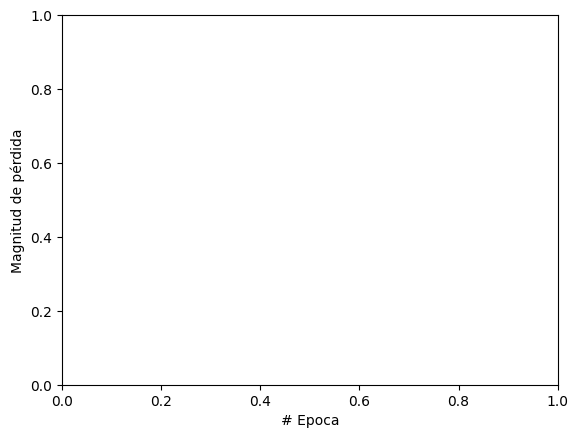

In [32]:
import matplotlib.pyplot as plt
plt.xlabel("# Epoca")
plt.ylabel("Magnitud de pérdida")
plt.plot(historial.history["loss"])

In [13]:
print("Hagamos una predicción!")
entrada = np.array([50.0])
resultado = modelo.predict(entrada)
print("El resultado es " + str(resultado) + " fahrenheit!")

Hagamos una predicción!
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
El resultado es [[121.84997]] fahrenheit!


In [14]:
print("Variables internas del modelo")
#print(capa.get_weights())
print(oculta1.get_weights())
print(oculta2.get_weights())
print(salida.get_weights())

Variables internas del modelo
[array([[ 0.85342574,  0.01637453, -0.46047562]], dtype=float32), array([ 3.5686038, -3.5213246, -3.5827363], dtype=float32)]
[array([[-0.4891038 , -0.52917874, -0.7637865 ],
       [ 0.5287621 ,  1.6281859 , -0.33985746],
       [-0.92290026,  1.113293  , -0.57998455]], dtype=float32), array([-2.2763093, -3.5616324, -3.399291 ], dtype=float32)]
[array([[-0.04103692],
       [-1.8275778 ],
       [-0.21797   ]], dtype=float32), array([3.497362], dtype=float32)]


In [16]:
#Guardamos el modelo de la red neuronal para poderlo usar en Web 2 o Web3 
modelo.save("celcius_a_farenheit.h5")
!dir

GradosCelcius.ipynb  celcius_a_farenheit.h5


In [17]:
# Para usarlo en Web2 o Web3 hay que convertirlo en tensorflow.js
# para ello instalamos la libreria  tensorflow.js desde la terminar o aqui mismo
# 1.- Install TensowflowJS  - > !pip install tensorflowjs
# 2.- Crear una carpeta dentro del folder donde se guardaran los resultados. -> !mkdir carpeta_salida
!mkdir carpeta_salida
# 

In [19]:
# Ejecutamos el comando de conversion. 
# !tensorflowjs_converter --input_format keras <nombre_archivi.h5> <carpeta_salida>
!tensorflowjs_converter --input_format keras celcius_a_farenheit.h5 carpeta_salida

2024-05-07 21:47:52.477043: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2024-05-07 21:47:52.486272: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2024-05-07 21:47:52.630332: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-05-07 21:47:54.448847: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
failed to lookup keras version from the file,
    this is likely a weight only file


Se puede visualizar un ejemplo de su funcionamiento en : 
https://web2.mm4.me/MachineLearning/Web2_App/
